# How the covariance moves unobserved components during the reverse transport

One Lorenz-96 analysis, instrumented. Four state components are followed through the reverse
ODE: one observed, $x_{20}$, and three unobserved neighbours, $x_{21}$-$x_{23}$.

Three runs share the same forecast ensemble, the same cycle and the same terminal noise, and
differ only in what the analysis may use:

| run | covariance | observations |
|---|---|---|
| C, 25 % | localized $\mathbf{C}$ | 25 % of the state |
| I, 25 % | $\mathbf{C} = \mathbf{I}$ | 25 % of the state |
| I, 100 % | $\mathbf{C} = \mathbf{I}$ | every component |

Configuration is that of the linear experiment: $d = 40$, $N_e = 20$,
$\sigma_{\rm obs} = 0.1$, $\Delta t_{\rm obs} = 0.2$. Each member is replicated 10 times, so
each panel shows 200 trajectories.

**Produces** Figure 2 of the manuscript. Set `RUN_SIMULATION = False` to rebuild it from
`mechanism_cache.npz`.

## 1. Configuration

In [1]:
import numpy as np, json, os, time
import matplotlib
import matplotlib.pyplot as plt

D            = 40
F_FORCING    = 8.0
DT_TRUTH     = 0.01
DT_MODEL     = 0.02
DT_OBS       = 0.2         # 24 h cycle
SPINUP_STEPS = 2000
OBS_STRIDE   = 4           # 25 % coverage
SIGMA_OBS    = 0.1
K            = 20
SIGMA_INIT   = 0.5
N_CYCLES     = 40
EPS_C        = 1e-6
STD_FLOOR    = 1e-8

# CI-EnSF at the setting tuned in the linear experiment
GAMMA0, L_LOC, CTRL = 0.05, 4.0, "clip"
N_STEPS, T_STOP     = 400, 0.1

obs_idx  = np.arange(0, D, OBS_STRIDE)
obs_mask = np.zeros(D, bool); obs_mask[obs_idx] = True
unobs_idx = np.setdiff1d(np.arange(D), obs_idx)
Q        = obs_idx.size
R_DIAG   = np.full(Q, SIGMA_OBS**2)

RUN_SIMULATION = False
CACHE = "mechanism_cache.npz"

def save_cache(**kw):
    # compressed: the JSON payloads are stored by numpy as UTF-32, four bytes per
    # character, so an uncompressed cache is several times larger than it needs to be.
    np.savez_compressed(CACHE, **{k: (v if isinstance(v, np.ndarray) else np.array(json.dumps(v)))
                                  for k, v in kw.items()})
def load_cache():
    z = np.load(CACHE, allow_pickle=False)
    return {k: (json.loads(str(z[k])) if z[k].dtype.kind in "US" else z[k]) for k in z.files}



## 2. Model, localization and $\mathbf{C}$

$\mathbf{C}$ is the localized correlation matrix of the standardized ensemble, Eq. (17).
The three runs differ only in whether the analysis uses it or $\mathbf{C}=\mathbf{I}$.


In [2]:
def l96_rhs(x):
    return (np.roll(x, -1, -1) - np.roll(x, 2, -1))*np.roll(x, 1, -1) - x + F_FORCING

def rk4(x, dt, steps):
    for _ in range(steps):
        k1 = l96_rhs(x); k2 = l96_rhs(x + 0.5*dt*k1)
        k3 = l96_rhs(x + 0.5*dt*k2); k4 = l96_rhs(x + dt*k3)
        x = x + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)
    return x

M_op    = lambda v: v
M_prime = lambda v: np.ones_like(v)

def make_truth(seed, n_cycles):
    rng = np.random.default_rng(seed)
    x = rk4(rng.normal(scale=3.0, size=D), DT_TRUTH, SPINUP_STEPS)
    T = np.empty((n_cycles, D))
    for n in range(n_cycles):
        T[n] = x; x = rk4(x, DT_TRUTH, int(round(DT_OBS/DT_TRUTH)))
    return T, T[0] + SIGMA_INIT*rng.standard_normal((K, D)), rng

def rho_gc(rr):
    rr = np.abs(np.asarray(rr, float)); out = np.zeros_like(rr)
    n = rr <= 1; x = rr[n]; out[n] = 1 - (5/3)*x**2 + (5/8)*x**3 + 0.5*x**4 - 0.25*x**5
    f = (rr > 1) & (rr < 2); x = rr[f]
    out[f] = 4 - 5*x + (5/3)*x**2 + (5/8)*x**3 - 0.5*x**4 + x**5/12 - 2/(3*x)
    return out

DIST = np.minimum(np.abs(np.arange(D)[:,None] - np.arange(D)[None,:]),
                  D - np.abs(np.arange(D)[:,None] - np.arange(D)[None,:]))
TAPER = (rho_gc(DIST/L_LOC) > 0).astype(float)

def build_C(U):
    A  = U - U.mean(0)
    P  = TAPER*((A.T @ A)/(K - 1))
    Cm = (P + EPS_C*np.eye(D))/(1.0 + EPS_C)
    lam, QB = np.linalg.eigh(0.5*(Cm + Cm.T)); lam = np.maximum(lam, 0.0)
    return (QB*lam) @ QB.T, QB*np.sqrt(lam)

def standardize(Xf):
    shift = Xf.mean(0); std = np.maximum(Xf.std(0, ddof=1), STD_FLOOR)
    return shift, std, (Xf - shift)/std



## 3. The reverse ODE, instrumented

`cvt_reverse` records, at every step, the value of the four tracked components for every
trajectory and the two contributions to the velocity: the prior transport and
$\mathbf{C}\mathbf{s}_{\rm lik}$. `C_override` and `obs_override` select the three runs.

In [3]:
def cvt_reverse(Xf, y_full, xt, rng, gamma, C_override=None, obs_override=None,
                z_init=None, record=None, n_rep=1):
    """One CI-EnSF analysis with optional overrides, returning (Xa, trace).

    C_override   : (d,d) to use instead of the localized ensemble correlation
    obs_override : index array to use instead of obs_idx (for the 100 % run)
    z_init       : (K,d) terminal state in STANDARDIZED coordinates, shared across runs
    record       : list of state indices whose trajectory and increment split to log
    n_rep        : replicas per ensemble member.  Member k's analysis is a deterministic
                   function of (u^k, z^k(1), y^k), and the last two are random, so drawing
                   n_rep independent pairs per member samples the conditional law of the
                   analysis GIVEN that member.  With n_rep = 10 the density in figure 1 is
                   estimated from 200 points per pseudo-time instead of 20.  These replicas
                   are NOT the analysis ensemble -- the filter still carries K = 20 members;
                   they are a Monte-Carlo enlargement of the same distribution, used only to
                   make the density and the conditional mean less noisy.
    """
    shift, std, U0 = standardize(Xf)
    Cm, Lm = build_C(U0)
    U = np.repeat(U0, n_rep, axis=0) if n_rep > 1 else U0     # (K*n_rep, d)
    M = U.shape[0]
    if C_override is not None: Cm = C_override
    oi = obs_idx if obs_override is None else obs_override
    Rl = np.full(oi.size, SIGMA_OBS**2)
    yo = y_full[oi]
    off_o, std_o = shift[oi], std[oi]
    yk = yo + rng.normal(scale=np.sqrt(Rl), size=(M, oi.size))
    dt = (1.0 - T_STOP)/N_STEPS
    z  = (rng.standard_normal((M, D)) @ Lm.T) if z_init is None else z_init.copy()
    tr = {"t": [], "x": [], "prior": [], "lik": []}
    for n in range(N_STEPS):
        t  = 1.0 - (n + 1)*dt
        c  = (1.0 - t)**2*gamma + t
        bb = 1.0/(1.0 - t); s2 = (1.0 + t)/(1.0 - t)
        Bs_prior = -(z - (1.0 - t)*U)/c
        xs  = std_o*z[:, oi] + off_o
        lik = np.zeros_like(z)
        lik[:, oi] = -(std_o*M_prime(xs))*(M_op(xs) - yk)/Rl
        Bs_lik = (1.0 - t)*(lik @ Cm)
        if record is not None:
            tr["t"].append(t)
            tr["x"].append((std*z + shift)[:, record].copy())
            # the two contributions to dz/dt, in PHYSICAL units, at the recorded components
            tr["prior"].append((0.5*s2*std*Bs_prior)[:, record].mean(0).copy())
            tr["lik"].append((0.5*s2*std*Bs_lik)[:, record].mean(0).copy())
        z = z - dt*(-bb*z - 0.5*s2*(Bs_prior + Bs_lik))
    Xa = std*z + shift
    if record is not None:
        tr = {k: np.array(v) for k, v in tr.items()}
    return Xa, tr

# the innovation controller, as in the linear experiment
W_SMOOTH, TRIG, P_GAIN, DECAY, G_LO, G_HI = 0.3, 1.0, 0.5, 0.97, 0.05, 0.5
def innovation_ratio(Xf, y):
    hx = M_op(Xf[:, obs_idx]); d = y[obs_idx] - hx.mean(0)
    return float(d @ d / np.sum((1.0 + 1.0/K)*hx.var(0, ddof=1) + R_DIAG))
def update_gamma(g, rho_s):
    if CTRL == "off": return g
    if rho_s > TRIG:  return min(g*(rho_s/TRIG)**P_GAIN, G_HI)
    return max(g*DECAY, G_LO) if CTRL == "clip" else g


## 4. Choosing the cycle

The cycle is picked by a fixed rule — the one with the largest forecast error at unobserved
components over the first 25 cycles of seed 0 — so the choice does not depend on the result.

In [4]:
SEED = 0

def cycling(seed, n_cycles=N_CYCLES):
    """Run the filter normally, recording the forecast state and gamma at each cycle."""
    T, X, rng = make_truth(seed, n_cycles)
    gamma, rho_s, hist = GAMMA0, 1.0, []
    for n in range(n_cycles):
        # observations are generated for EVERY component and the analysis takes the subset
        # it is allowed to see.  Run 3 below needs the full vector; generating it here keeps
        # the noise realisation identical between the 25 % and 100 % runs wherever they overlap.
        y = M_op(T[n]) + rng.normal(scale=SIGMA_OBS, size=D)
        rho_s = (1 - W_SMOOTH)*rho_s + W_SMOOTH*innovation_ratio(X, y)
        gamma = update_gamma(gamma, rho_s)
        hist.append(dict(n=n, Xf=X.copy(), truth=T[n].copy(), y=y.copy(), gamma=gamma,
                         err_unobs=float(np.abs(X.mean(0)[unobs_idx] - T[n][unobs_idx]).mean())))
        X, _ = cvt_reverse(X, y, T[n], rng, gamma)
        X = rk4(X, DT_MODEL, int(round(DT_OBS/DT_MODEL)))
    return hist

if RUN_SIMULATION:
    HIST = cycling(SEED)
    errs = np.array([h["err_unobs"] for h in HIST])
    PICK = int(np.argmax(errs))      # the fixed rule: largest unobserved forecast error
    SEL = HIST[PICK]
else:
    PICK = int(load_cache()["pick"])

## 5. The four states

One observed component and its three unobserved neighbours.

In [5]:
if RUN_SIMULATION:
    J = int(obs_idx[len(obs_idx)//2])     # an observed component near the middle
    GROUP = [J, J+1, J+2, J+3]            # plain ints: they are written to JSON below
    Xf, xt, y = SEL["Xf"], SEL["truth"], SEL["y"]   # y holds all D components; see above
else:
    # The forecast ensemble and the truth of the selected cycle are cached, so the cells
    # below index exactly what the simulation produced.  `y` is not restored: only the
    # RUN_SIMULATION branch of the next cell needs it.
    _c    = load_cache()
    GROUP = [int(g) for g in _c["group"]]
    J     = GROUP[0]
    Xf    = np.asarray(_c["xf"], float)
    xt    = np.asarray(_c["xt"], float)


## 6. The three runs

Same forecast ensemble, same terminal noise, 10 replicas per member.

In [6]:
if RUN_SIMULATION:
    _, _, U0 = standardize(Xf)
    _, Lm0 = build_C(U0)
    N_REP  = 10            # replicas per member; see cvt_reverse's docstring
    Z_INIT = np.random.default_rng(12345).standard_normal((K*N_REP, D)) @ Lm0.T   # shared

    RUNS, TRACE = {}, {}
    CONFIGS = [("C, 25 %",  None,           None),
               ("I, 25 %",  np.eye(D),      None),
               ("I, 100 %", np.eye(D),      np.arange(D))]
    for tag, Bov, oov in CONFIGS:
        # a fresh rng per run so the observation perturbations are drawn the same way;
        # the same seed makes them identical wherever the two networks overlap
        Xa, tr = cvt_reverse(Xf, y, xt, np.random.default_rng(777), SEL["gamma"],
                             C_override=Bov, obs_override=oov,
                             z_init=Z_INIT, record=GROUP, n_rep=N_REP)
        RUNS[tag] = Xa; TRACE[tag] = {k: v.tolist() for k, v in tr.items()}
        print("%-9s done  (%d trajectories = %d members x %d replicas)"
              % (tag, Xa.shape[0], K, N_REP))
else:
    _c     = load_cache()
    N_REP  = int(_c["n_rep"])
    RUNS   = {k: np.asarray(v, float) for k, v in _c["runs"].items()}
    TRACE  = _c["trace"]
    for tag, Xa in RUNS.items():
        print("%-9s done  (%d trajectories = %d members x %d replicas)"
              % (tag, Xa.shape[0], K, N_REP))

C, 25 %   done  (200 trajectories = 20 members x 10 replicas)
I, 25 %   done  (200 trajectories = 20 members x 10 replicas)
I, 100 %  done  (200 trajectories = 20 members x 10 replicas)


## 7. Figure 2

One observed state and three unobserved neighbours through one analysis. All three columns
start from the same forecast ensemble and the same terminal noise, so the only difference is
what the analysis may use: the left column is CI-EnSF with its localized $\mathbf{C}$ and
25 % of the state observed, the centre is the same observations with
$\mathbf{C} = \mathbf{I}$, and the right is $\mathbf{C} = \mathbf{I}$ with every component
observed, as a full-information reference.

Pseudo-time runs from $t = 1$ to $t_{\rm stop} = 0.1$. Shading is the density of the 200
trajectories, the solid curve their mean, the dashed line the truth, and the strip below each
panel the final analysis density.

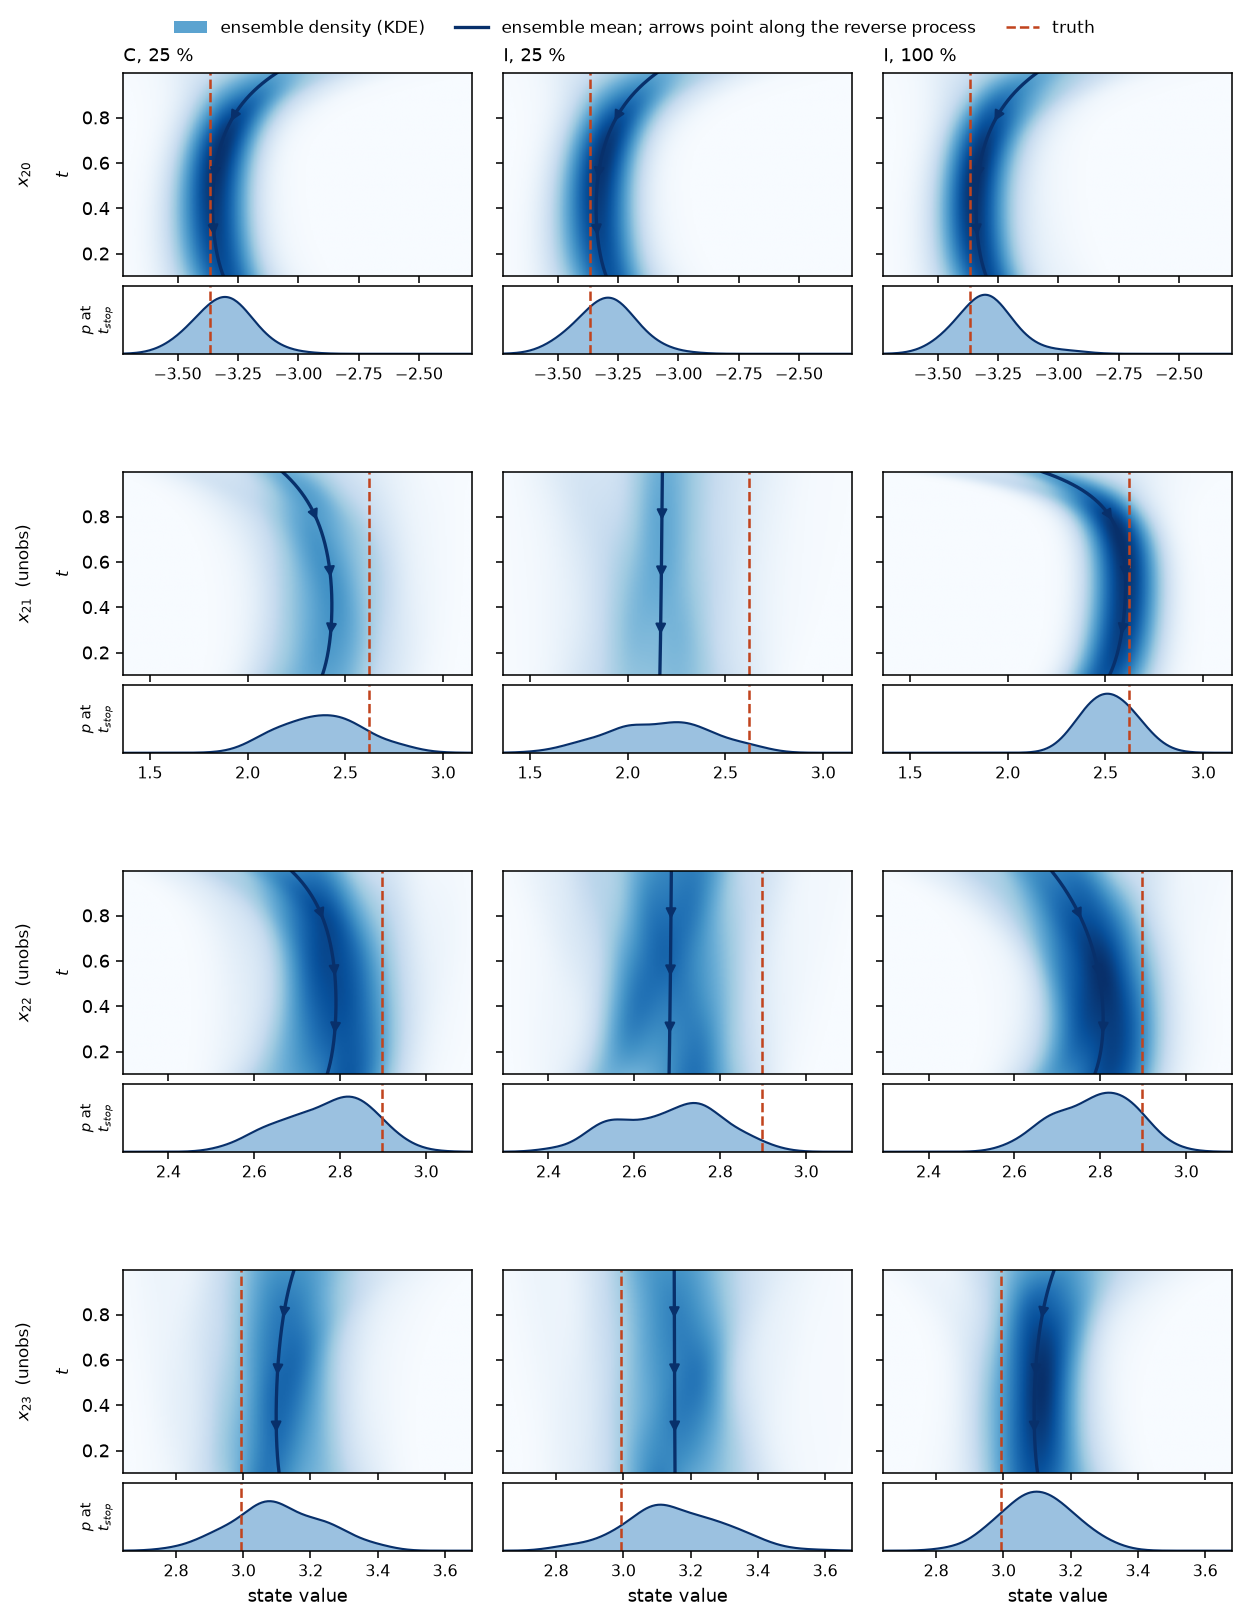

In [7]:
plt.rcParams.update({"font.size":9,"legend.frameon":False,"figure.dpi":140,
                     "savefig.bbox":"tight","lines.linewidth":1.2})

def kde_slice(vals, grid, bw):
    """Gaussian kernel density of the member values on `grid`, one pseudo-time at a time."""
    d = (grid[None, :] - vals[:, None])/bw
    return np.exp(-0.5*d**2).sum(0)/(len(vals)*bw*np.sqrt(2*np.pi))

TAGS = list(RUNS)
BW_FRAC = 0.05          # kernel width as a fraction of the row's value range.  Fixed, not
                        # adapted per time slice, so a CONTRACTING ensemble shows up as a
                        # narrowing band rather than being normalised away.  Tested at
                        # 2/5/10/18 %: 2 % still resolves individual trajectories, 10 % and
                        # above wash the contraction out.

# Each row of panels is split in two: the density of the reverse trajectories above, and the
# density at the FINAL pseudo-time below, so that where the truth sits relative to the
# analysis distribution can be read directly instead of inferred from the band.
gs_rows = []
fig = plt.figure(figsize=(8.8, 2.9*len(GROUP)))
outer = fig.add_gridspec(len(GROUP), 3, hspace=0.42, wspace=0.09,
                         top=0.955, bottom=0.045, left=0.085, right=0.985)
for ri, g in enumerate(GROUP):
    allv = np.concatenate([np.asarray(TRACE[t]["x"])[:, :, ri].ravel() for t in TAGS]
                          + [[xt[g]]])
    lo, hi = allv.min(), allv.max(); pad = 0.06*(hi - lo); lo -= pad; hi += pad
    grid = np.linspace(lo, hi, 240); bw = BW_FRAC*(hi - lo)
    imgs = [np.array([kde_slice(np.asarray(TRACE[t]["x"])[s, :, ri], grid, bw)
                      for s in range(len(TRACE[t]["t"]))]) for t in TAGS]
    vmax = max(im.max() for im in imgs)
    fmax = max(kde_slice(np.asarray(TRACE[t]["x"])[-1, :, ri], grid, bw).max() for t in TAGS)
    for cj, tag in enumerate(TAGS):
        tt = np.asarray(TRACE[tag]["t"])
        xs = np.asarray(TRACE[tag]["x"])[:, :, ri]
        inner = outer[ri, cj].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.07)
        a  = fig.add_subplot(inner[0])
        b  = fig.add_subplot(inner[1], sharex=a)
        # --- trajectory density
        a.imshow(imgs[cj], origin="upper", aspect="auto", cmap="Blues", vmin=0, vmax=vmax,
                 extent=[lo, hi, tt[-1], tt[0]])
        mu = xs.mean(1)
        a.plot(mu, tt, color="#08306b", lw=1.7)
        # short arrow heads laid on the mean path, pointing the way the reverse process
        # runs (t decreasing, i.e. downward with this axis orientation)
        _k = max(1, len(tt)//50)
        for _f in (0.22, 0.50, 0.78):
            _s0 = int(_f*(len(tt) - 1)); _s1 = min(_s0 + _k, len(tt) - 1)
            a.annotate("", xy=(mu[_s1], tt[_s1]), xytext=(mu[_s0], tt[_s0]),
                       arrowprops=dict(arrowstyle="-|>", color="#08306b", lw=1.1,
                                       mutation_scale=11, shrinkA=0, shrinkB=0))
        a.axvline(xt[g], color="#c1441e", ls="--", lw=1.3)
        a.set_xlim(lo, hi); a.set_ylim(tt[-1], tt[0])   # t = 1 at the top (asserted below)
        a.tick_params(labelbottom=False)
        if cj: a.tick_params(labelleft=False)
        if ri == 0: a.set_title(tag, loc="left", fontsize=9.5)
        if cj == 0: a.set_ylabel("$x_{%d}$%s\n\n$t$" % (g, "" if g in obs_idx else "  (unobs)"),
                                 fontsize=8.5)
        # --- density at the final pseudo-time
        fd = kde_slice(xs[-1], grid, bw)
        b.fill_between(grid, fd, color="#4a8fc7", alpha=.55, lw=0)
        b.plot(grid, fd, color="#08306b", lw=1.1)
        b.axvline(xt[g], color="#c1441e", ls="--", lw=1.3)
        b.set_xlim(lo, hi); b.set_ylim(0, fmax*1.15); b.set_yticks([])
        if cj == 0: b.set_ylabel("$p$ at\n$t_{stop}$", fontsize=7.5)
        b.tick_params(labelbottom=True, labelsize=8)
        if ri == len(GROUP)-1: b.set_xlabel("state value")
        gs_rows.append((a, b))

# consistency checks.  A symmetric KDE preserves the mean, so the density's mean must equal
# the sample mean; and the time axis must run from t = 1 at the top down to t_stop.  Both
# were added after errors that produced a plausible-looking but wrong figure.
_ri = 1; _g = GROUP[_ri]
_allv = np.concatenate([np.asarray(TRACE[t]["x"])[:, :, _ri].ravel() for t in TAGS] + [[xt[_g]]])
_lo, _hi = _allv.min(), _allv.max(); _pad = 0.06*(_hi-_lo); _lo -= _pad; _hi += _pad
_grid = np.linspace(_lo, _hi, 240); _bw = BW_FRAC*(_hi-_lo)
_xs = np.asarray(TRACE[TAGS[0]]["x"])[:, :, _ri]
for _s in (0, len(_xs)//2, len(_xs)-1):
    _d = kde_slice(_xs[_s], _grid, _bw)
    assert abs(float((_grid*_d).sum()/_d.sum()) - float(_xs[_s].mean())) < 0.02*(_hi-_lo), \
        "KDE mean disagrees with the sample mean at step %d" % _s
_a0 = gs_rows[0][0]; _yb, _yt = _a0.get_ylim(); _tt = np.asarray(TRACE[TAGS[0]]["t"])
assert _yt > _yb and abs(_yt - _tt[0]) < 1e-9 and abs(_yb - _tt[-1]) < 1e-9, \
    "time axis orientation is wrong: (%.4f, %.4f)" % (_yb, _yt)
# one legend for all 12 panels, above the column titles
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
fig.legend(handles=[Patch(facecolor=plt.get_cmap("Blues")(0.55), edgecolor="none",
                          label="ensemble density (KDE)"),
                    Line2D([], [], color="#08306b", lw=1.7, label="ensemble mean; arrows "
                           "point along the reverse process"),
                    Line2D([], [], color="#c1441e", lw=1.3, ls="--", label="truth")],
           loc="lower center", bbox_to_anchor=(0.5, 0.968), ncol=3, fontsize=8.5,
           handlelength=2.0, columnspacing=1.8)

fig.savefig("mechanism_fig2.pdf"); plt.show()

if RUN_SIMULATION:
    save_cache(pick=int(PICK), group=[int(g) for g in GROUP], trace=TRACE,
               n_rep=int(N_REP), xf=Xf.tolist(), xt=xt.tolist(),
               runs={k: v.tolist() for k, v in RUNS.items()})